# Paper 16: An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT)
**Authors**: Alexey Dosovitskiy et al. (Google Research, Brain Team, ICLR 2021)

---

## 1. The Historical Breaking Point: The 2D Inductive Bias Monopoly
For nearly a decade, Computer Vision relied entirely on CNNs (ResNet, ConvNet) with hardcoded inductive biases:
- **Locality**: Filters only process adjacent pixels.
- **Translation Equivariance**: Shifting an image yields shifted feature maps.

While helpful on small datasets, these inductive constraints limit scaling on massive datasets (JFT-300M, LAION). Convolutions cannot dynamically route information globally across distant regions in a single layer.

## 2. The Thought Experiment: "An Image is Worth 16x16 Words"
Instead of pixel-level attention ($224 \times 224 = 50,176$ tokens, too expensive!):
- Slice the image into non-overlapping $P \times P$ patches (e.g. $16 \times 16$).
- Flatten and linearly project each patch into embedding dimension $D$.
- Prepend a learnable `[CLS]` token and add 1D positional embeddings.
- Process with a standard pure Transformer encoder stack!

$$\mathbf{z}_0 = [\mathbf{x}_{\text{class}} \,;\, \mathbf{x}_p^1 \mathbf{E} \,;\, \dots \,;\, \mathbf{x}_p^N \mathbf{E}] + \mathbf{E}_{\text{pos}}$$

In this notebook, you will test and verify:
1. `PatchEmbedding` (via strided 2D convolution)
2. `ViTAttention`, `ViTMLP`, and `ViTBlock`
3. Spatial position sensitivity (contrasting ViT with PointNet)
4. Full `ViT` classifier training

---
## Setup & Autoreload

In [2]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from model import (
    PatchEmbedding,
    ViTAttention,
    ViTMLP,
    ViTBlock,
    ViT,
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch version: 2.14.1+cpu
CUDA available: False


---
## 1. Visualizing Patchification
Demonstrating how a 2D image is sliced into discrete patches and fed as sequential tokens.

In [3]:
H, W, P = 32, 32, 8
patch_embed = PatchEmbedding(img_size=H, patch_size=P, in_channels=3, embed_dim=48)
patch_embed.eval()

sample_img = torch.rand(1, 3, H, W)
patches = patch_embed(sample_img)

print(f"Input image shape: {sample_img.shape}")
print(f"Number of patches: {patch_embed.num_patches} (Grid: {H//P} x {W//P})")
print(f"Output token sequence shape: {patches.shape}")
assert patches.shape == (1, 16, 48)
print("PatchEmbedding contract PASSED!")

Input image shape: torch.Size([1, 3, 32, 32])
Number of patches: 16 (Grid: 4 x 4)
Output token sequence shape: torch.Size([1, 16, 48])
PatchEmbedding contract PASSED!


---
## 2. Spatial Position Sensitivity (ViT vs PointNet)
In Paper #9 (PointNet), networks were designed to be **permutation-invariant** ($f(P x) = f(x)$).
In Vision Transformers, because positional embeddings $\mathbf{E}_{\text{pos}}$ encode spatial coordinates, rearranging image regions **must** change the token representations.

In [4]:
torch.manual_seed(42)
model = ViT(img_size=32, patch_size=8, in_channels=3, num_classes=5, embed_dim=32, depth=2, num_heads=2)
model.eval()

x1 = torch.randn(1, 3, 32, 32)
# Swap the top and bottom halves
x2 = torch.cat([x1[:, :, 16:, :], x1[:, :, :16, :]], dim=2)

with torch.no_grad():
    f1 = model.forward_features(x1)
    f2 = model.forward_features(x2)

diff = (f1 - f2).abs().max().item()
print(f"Feature difference when swapping image halves: {diff:.4f}")
assert diff > 0.1
print("Spatial position sensitivity verified!")

Feature difference when swapping image halves: 5.4917
Spatial position sensitivity verified!


---
## 3. Single-Batch Overfit (Image Classification)
Train `ViT` on a batch of synthetic images to confirm end-to-end gradient flow.

Epoch 15 | Loss: 0.3184
Epoch 30 | Loss: 0.1273
Epoch 45 | Loss: 0.0614
Epoch 60 | Loss: 0.0367


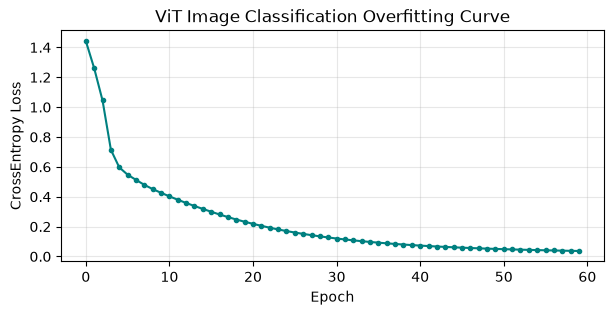

Overfit check PASSED! Final loss: 0.0367


In [5]:
torch.manual_seed(42)
B, C, H, W, num_classes = 4, 3, 32, 32, 4

model = ViT(
    img_size=H,
    patch_size=8,
    in_channels=C,
    num_classes=num_classes,
    embed_dim=64,
    depth=3,
    num_heads=4,
    drop_rate=0.0,
)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

images = torch.randn(B, C, H, W)
targets = torch.tensor([0, 1, 2, 3])

losses = []
for epoch in range(60):
    optimizer.zero_grad()
    logits = model(images)
    loss = criterion(logits, targets)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:2d} | Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, marker='o', markersize=3, color='teal')
plt.xlabel('Epoch')
plt.ylabel('CrossEntropy Loss')
plt.title('ViT Image Classification Overfitting Curve')
plt.grid(True, alpha=0.3)
plt.show()

assert losses[-1] < 0.05
print(f"Overfit check PASSED! Final loss: {losses[-1]:.4f}")